In [4]:
import os
from collections import Counter

DATA_DIR = r"C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder"   # change this if your dataset is somewhere else

ext_count = Counter()
folder_count = Counter()

for root, dirs, files in os.walk(DATA_DIR):
    for f in files:
        ext = os.path.splitext(f)[1].lower()
        ext_count[ext] += 1
        if ext in (".jpg", ".jpeg", ".png"):
            folder_count[root] += 1

print("File types:", dict(ext_count))
print("\nImages per folder:")
for folder, n in folder_count.items():
    print(f"  {folder}: {n}")
print("\nTotal images:", sum(folder_count.values()))

File types: {'.txt': 2, '.jpg': 110}

Images per folder:
  C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder\test\egg: 11
  C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder\train\egg: 75
  C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder\train\Unlabeled: 2
  C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder\valid\egg: 22

Total images: 110


In [5]:
# pip install imagehash pillow
import os, glob
import imagehash
from PIL import Image

DATA_DIR = r"C:\Users\k nithin\OneDrive\Desktop\CV intern task\egg.v1i.folder"

paths = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True))
print("Images found:", len(paths))

hashes = {p: imagehash.phash(Image.open(p)) for p in paths}

# Union-find to group images connected by a small hash distance
parent = {p: p for p in paths}
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
def union(a, b):
    parent[find(a)] = find(b)

THRESH = 10   # we may tune this after looking at results
close_pairs = []
for i, a in enumerate(paths):
    for b in paths[i+1:]:
        d = hashes[a] - hashes[b]
        if d <= THRESH:
            union(a, b)
            close_pairs.append((a, b, d))

clusters = {}
for p in paths:
    clusters.setdefault(find(p), []).append(p)

sizes = sorted((len(v) for v in clusters.values()), reverse=True)
print("Similar pairs:", len(close_pairs))
print("Number of clusters:", len(clusters))
print("Cluster sizes (largest first):", sizes[:15])

print("\nSample close pairs (distance):")
for a, b, d in sorted(close_pairs, key=lambda x: x[2])[:10]:
    print(d, os.path.basename(a), "<->", os.path.basename(b))

Images found: 110
Similar pairs: 1
Number of clusters: 109
Cluster sizes (largest first): [2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Sample close pairs (distance):
4 not_damaged_78_jpg.rf.d3a6e8624d192abc58ff7df9d5781bb5.jpg <-> not_damaged_27_jpg.rf.9eabbf76d6ac2d4caccb38b11e0d28ad.jpg


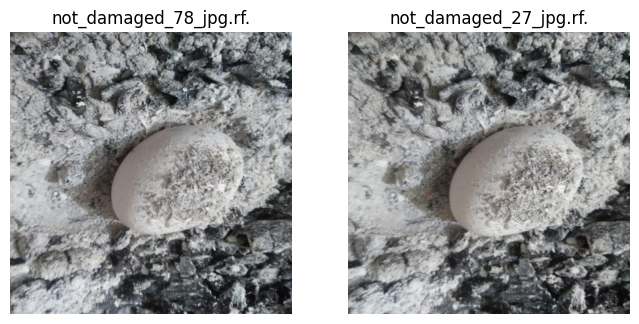

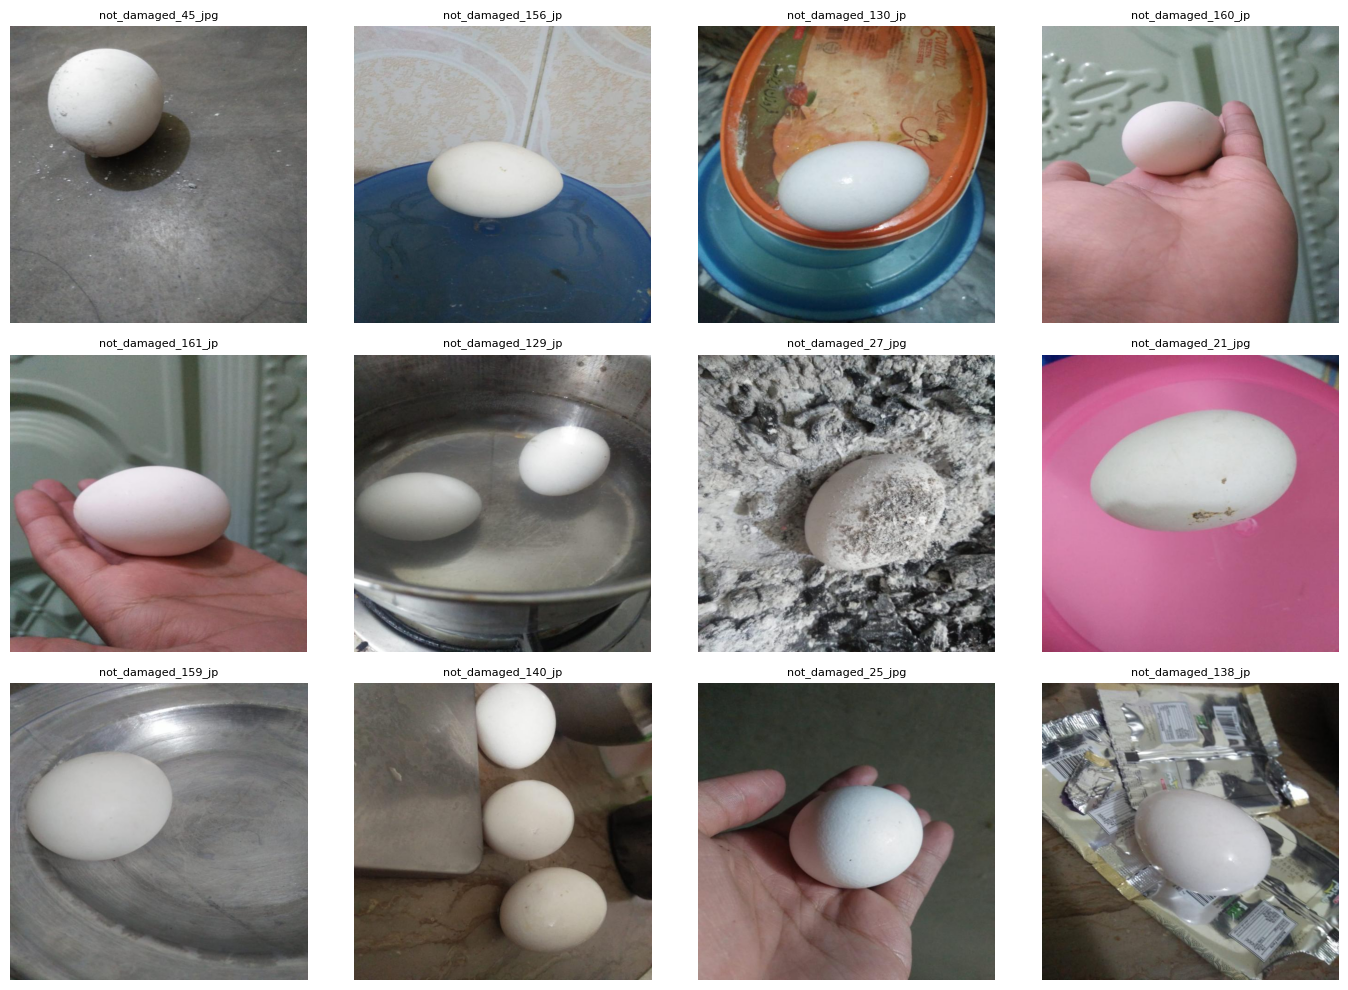

Counter({'not_damaged': 110})
Counter({(640, 640): 110})


In [6]:
import matplotlib.pyplot as plt
import random

# 1) The close pair
a, b = [p for p in close_pairs][0][:2]
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for axi, p in zip(ax, (a, b)):
    axi.imshow(Image.open(p)); axi.set_title(os.path.basename(p)[:22]); axi.axis("off")
plt.show()

# 2) Random grid of 12 images
random.seed(0)
sample = random.sample(paths, 12)
fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for axi, p in zip(ax.ravel(), sample):
    axi.imshow(Image.open(p)); axi.set_title(os.path.basename(p)[:18], fontsize=8); axi.axis("off")
plt.tight_layout(); plt.show()

# 3) Count by name prefix and image size
from collections import Counter
print(Counter("damaged" if "not_damaged" not in os.path.basename(p) else "not_damaged" for p in paths))
print(Counter(Image.open(p).size for p in paths))
